<a href="https://colab.research.google.com/github/cw1079/ML_Course26/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Connor Williams**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier, BaggingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# **Task 1: Load the dataset into a Pandas DataFrame from the source repository or course mirror, assigning appropriate column names.**

This loads the Pima Indians Diabetes dataset into a Pandas DataFrame and gives names to all nine columns. It then displays the first five rows and the datasets shape to make sure everything loaded correctly

In [12]:
RANDOM_STATE = 42
columns = ['pregnancies', 'glucose', 'blood_pressure', 'skin_thickness',
           'insulin', 'bmi', 'diabetes_pedigree', 'age', 'outcome']
#I have this link instead of downloading files
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
try:
    df = pd.read_csv(url, header=None, names=columns)
except Exception as error:
    raise RuntimeError('Dataset download failed. Check that Google Colab has internet access.') from error
print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (768, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# Task 2: Using structural inspection methods(head(), info(), describe())

This shows the use of head(), info(), and describe() to look at its structure and values. These functions show the different features and information such as averages and minimum values. The code also checks for zeros that could represent missing measurements.


In [26]:
print("First five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nZero values in each column:")
print((df == 0).sum())

First five rows:


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pregnancies        768 non-null    int64  
 1   glucose            768 non-null    int64  
 2   blood_pressure     768 non-null    int64  
 3   skin_thickness     768 non-null    int64  
 4   insulin            768 non-null    int64  
 5   bmi                768 non-null    float64
 6   diabetes_pedigree  768 non-null    float64
 7   age                768 non-null    int64  
 8   outcome            768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical summary:


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Zero values in each column:
pregnancies          111
glucose                5
blood_pressure        35
skin_thickness       227
insulin              374
bmi                   11
diabetes_pedigree      0
age                    0
outcome              500
dtype: int64


# **Task 3: Quantify and handle implicit missing values using SimpleImputer**

Some measurements contain zeros that are missing information rather than actual values. This code replaces those zeros with NaN and uses SimpleImputer to look at how missing values can be filled. This makes the data more accurate without deleting records of the patient


In [27]:
# Columns where zero represents a missing measurement
missing_cols = [
    "glucose", "blood_pressure", "skin_thickness",
    "insulin", "bmi"
]

df_clean = df.copy()

# Replace invalid zeros with NaN
df_clean[missing_cols] = df_clean[missing_cols].replace(0, np.nan)

# Count missing values
print("Missing values before imputation:")
print(df_clean.isnull().sum())

imputer = SimpleImputer(strategy="median")

imputed_example = imputer.fit_transform(df_clean[missing_cols])

print("\nExample after imputation:")
display(pd.DataFrame(
    imputed_example,
    columns=missing_cols
).head())

Missing values before imputation:
pregnancies            0
glucose                5
blood_pressure        35
skin_thickness       227
insulin              374
bmi                   11
diabetes_pedigree      0
age                    0
outcome                0
dtype: int64

Example after imputation:


,glucose,blood_pressure,skin_thickness,insulin,bmi
0,148.0,72.0,35.0,125.0,33.6
1,85.0,66.0,29.0,125.0,26.6
2,183.0,64.0,29.0,125.0,23.3
3,89.0,66.0,23.0,94.0,28.1
4,137.0,40.0,35.0,168.0,43.1


# Task 4: Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.

This code separates the features and splits the dataset into both training and testing groups. ColumnTransformer, SimpleImputer and StandardScaler was used to create a pre processing pipeline to handle missing values and standardize numerical features

In [24]:
# Separate the features and target
X = df_clean.drop("outcome", axis=1)
y = df_clean["outcome"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_cols = X.columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Apply preprocessing to numerical features
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)

Training data: (614, 8)
Testing data: (154, 8)


# Task 5: Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models

Two Voting Classifiers are trained using Logistic Regression, Support Vector Classification and also Decision Tree models. Hard voting chooses the prediction made by the majority of models and the soft voting averages their predicted probabilities.

Hard Voting Accuracy: 0.7337662337662337
              precision    recall  f1-score   support

           0       0.77      0.84      0.80       100
           1       0.64      0.54      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.69       154
weighted avg       0.73      0.73      0.73       154

Soft Voting Accuracy: 0.7402597402597403
              precision    recall  f1-score   support

           0       0.78      0.83      0.81       100
           1       0.65      0.57      0.61        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.71       154
weighted avg       0.73      0.74      0.74       154



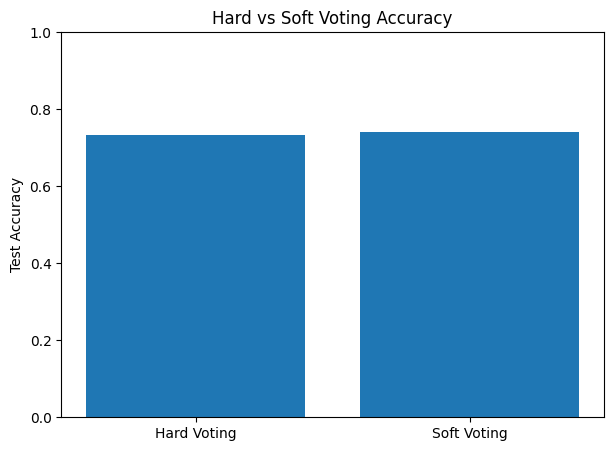

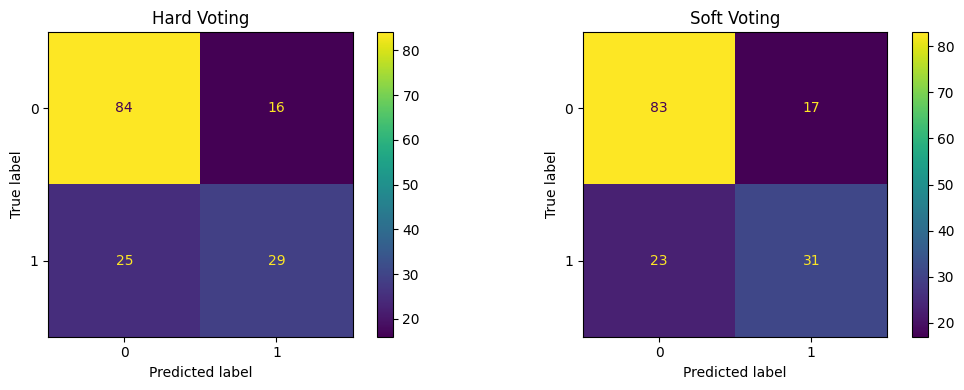

In [28]:
def create_models():
    return [
        ("logistic", LogisticRegression(max_iter=1000)),
        ("svc", SVC(probability=True, random_state=42)),
        ("tree", DecisionTreeClassifier(random_state=42))
    ]

# Create Hard Voting Classifier
hard_voting = VotingClassifier(
    estimators=create_models(),
    voting="hard"
)

# Create Soft Voting Classifier
soft_voting = VotingClassifier(
    estimators=create_models(),
    voting="soft"
)

hard_voting.fit(X_train_processed, y_train)
soft_voting.fit(X_train_processed, y_train)

hard_pred = hard_voting.predict(X_test_processed)
soft_pred = soft_voting.predict(X_test_processed)

# Calculate test accuracy
hard_accuracy = accuracy_score(y_test, hard_pred)
soft_accuracy = accuracy_score(y_test, soft_pred)

# Display evaluation results
print("Hard Voting Accuracy:", hard_accuracy)
print(classification_report(y_test, hard_pred))

print("Soft Voting Accuracy:", soft_accuracy)
print(classification_report(y_test, soft_pred))

plt.figure(figsize=(7, 5))
plt.bar(
    ["Hard Voting", "Soft Voting"],
    [hard_accuracy, soft_accuracy]
)
plt.title("Hard vs Soft Voting Accuracy")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.show()

# confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, hard_pred, ax=axes[0]
)
axes[0].set_title("Hard Voting")

ConfusionMatrixDisplay.from_predictions(
    y_test, soft_pred, ax=axes[1]
)
axes[1].set_title("Soft Voting")

plt.tight_layout()
plt.show()

# Task 6: Train a Bagging Classifier using decision tree base estimators

This trains a Bagging Classifier using multiple Decision Trees and each are learning from a randomly selected part of the training data. The code uses out-of-bag evaluation to look at performance using observations excluded from  bootstrap samples. The OOB score is then compared with test accuracy using a bar graph to see how the model performs.

OOB Accuracy: 0.755700325732899
Test Accuracy: 0.7207792207792207

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.83      0.79       100
           1       0.62      0.52      0.57        54

    accuracy                           0.72       154
   macro avg       0.69      0.67      0.68       154
weighted avg       0.71      0.72      0.71       154



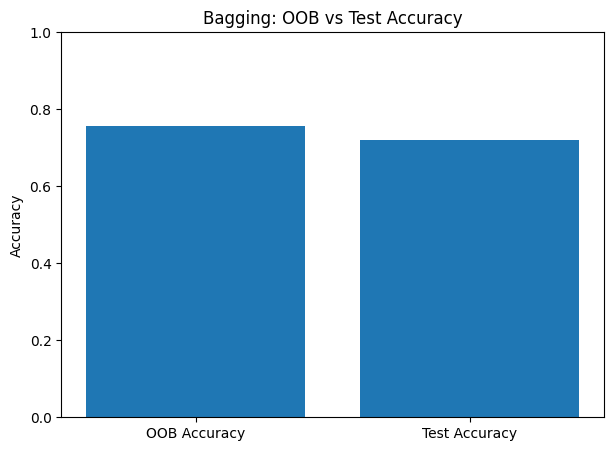

In [29]:

# Create Bagging Classifier using Decision Trees
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

# Train model
bagging.fit(X_train_processed, y_train)

# Predict testing data
bagging_pred = bagging.predict(X_test_processed)

# Calculate OOB and test accuracy
oob_accuracy = bagging.oob_score_
bagging_accuracy = accuracy_score(y_test, bagging_pred)

print("OOB Accuracy:", oob_accuracy)
print("Test Accuracy:", bagging_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, bagging_pred))

plt.figure(figsize=(7, 5))
plt.bar(
    ["OOB Accuracy", "Test Accuracy"],
    [oob_accuracy, bagging_accuracy]
)

plt.title("Bagging: OOB vs Test Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

# Task 7: Train a Random Forest Classifier configured with feature subsetting

This trains a Random Forest Classifier that combines multiple Decision Trees while randomly selecting features. It checks the model using test accuracy and a classification report to measure its prediction performance and a horizontal bar graph also shows which medical features contributed most to the model's predictions

Random Forest Accuracy: 0.7727272727272727

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.86      0.83       100
           1       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.77      0.77      0.77       154



,Feature,Importance
1,glucose,0.272616
5,bmi,0.163688
6,diabetes_pedigree,0.124927
7,age,0.113057
4,insulin,0.089395
2,blood_pressure,0.084337
0,pregnancies,0.080793
3,skin_thickness,0.071187


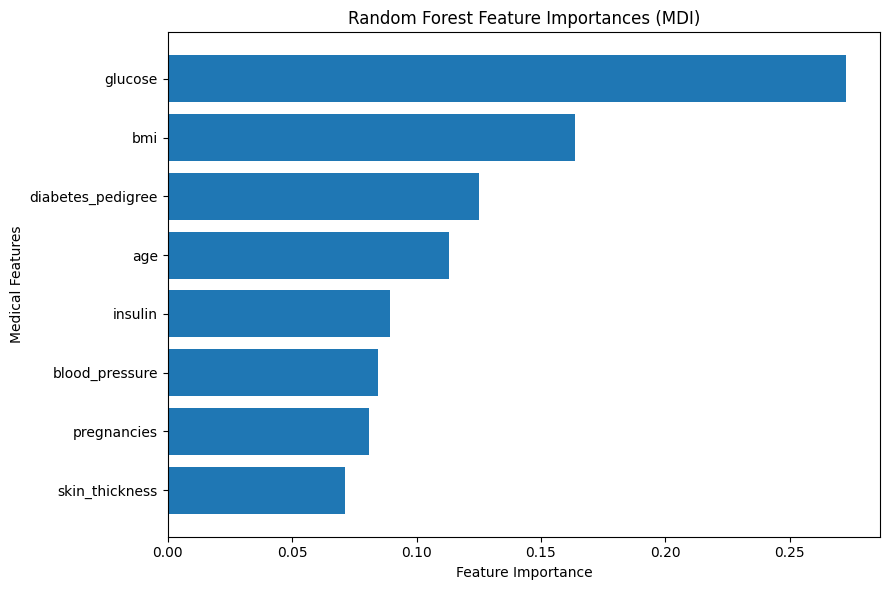

In [30]:

# Create Random Forest Classifier
random_forest = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest.fit(X_train_processed, y_train)

rf_pred = random_forest.predict(X_test_processed)

rf_accuracy = accuracy_score(y_test, rf_pred)

# Display evaluation results
print("Random Forest Accuracy:", rf_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

importances = random_forest.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": numeric_cols,
    "Importance": importances
}).sort_values("Importance")

# Display feature importance table
display(feature_importance.sort_values(
    "Importance", ascending=False
))

# Plot feature importances
plt.figure(figsize=(9, 6))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest Feature Importances (MDI)")
plt.xlabel("Feature Importance")
plt.ylabel("Medical Features")
plt.tight_layout()
plt.show()

# Task 8: Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting

This code trains a AdaBoost Classifier using decision stumps that learn sequentially which gives  more attention to observations that were seen as incorrect. The code calculates training and testing accuracy to evaluate how well the model performs on both familiar and data that has not been seen. A bar graph compares these results to show whether the model shows signs of overfitting.

AdaBoost Training Accuracy: 0.7980456026058632
AdaBoost Test Accuracy: 0.7467532467532467

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.82       100
           1       0.67      0.54      0.60        54

    accuracy                           0.75       154
   macro avg       0.72      0.70      0.71       154
weighted avg       0.74      0.75      0.74       154



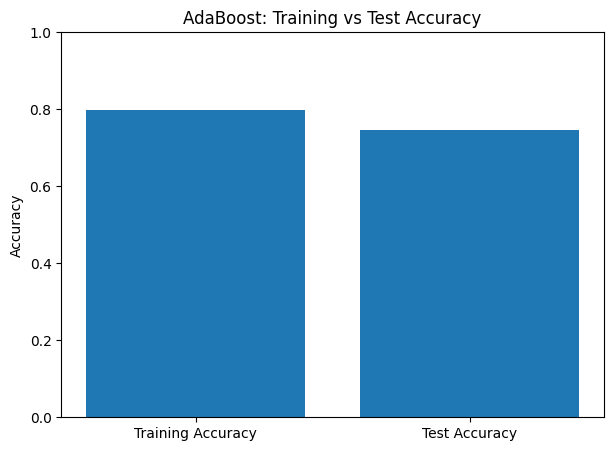

In [31]:
# Create AdaBoost using decision stumps
adaboost = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

adaboost.fit(X_train_processed, y_train)

ada_train_pred = adaboost.predict(X_train_processed)
ada_test_pred = adaboost.predict(X_test_processed)

# Calculate training accuracy
ada_train_accuracy = accuracy_score(
    y_train, ada_train_pred
)

# Calculate testing accuracy
ada_test_accuracy = accuracy_score(
    y_test, ada_test_pred
)

# Display accuracy scores
print("AdaBoost Training Accuracy:", ada_train_accuracy)
print("AdaBoost Test Accuracy:", ada_test_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, ada_test_pred))

# Plot training vs testing accuracy
plt.figure(figsize=(7, 5))
plt.bar(
    ["Training Accuracy", "Test Accuracy"],
    [ada_train_accuracy, ada_test_accuracy]
)

plt.title("AdaBoost: Training vs Test Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()